# Intro

* The impact of learning rate on fine-tuning
* Why quantitative measures of LLM training are insufficient on their own

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, GPT2Tokenizer
import requests

# vector plots
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [ ]:
# load GPT2 adn Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

# hyperparameters
seq_len = 256 # max sequence length
batch_size = 16

# use GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

# Train and Evaluate the Model

In [ ]:
# tokenize Gulliver's travel
text = requests.get('https://www.gutenberg.org/cache/epub/829/pg829.txt').text
gt_tokens = tokenizer.encode(text, return_tensors='pt')[0]

# find the most frequent 100 tokens
uniq, counts = np.unique(gt_tokens, return_counts = True)
freq_idx = np.argsort(counts)[::-1]
top_100 = uniq[freq_idx[:100]]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (158340 > 1024). Running this sequence through the model will result in indexing errors


In [ ]:
def countFreqTokens(model):

  # random starting tokens
  num_reps = 10 # number of random repetitions
  num_toks = 100 # output length
  rand_starts = torch.randint(tokenizer.vocab_size, (num_reps, 1)).to(device)

  # generate some data
  out = model.generate(
      rand_starts,
      max_length = num_toks + 1,
      min_length = num_toks + 1,
      do_sample  = True,
      bad_words_ids = [tokenizer.encode(tokenizer.eos_token)],
      pad_token_id = tokenizer.encode(tokenizer.eos_token)[0]
  ).cpu()

  # return proportion
  return np.mean(100* np.isin(out[:,1:], top_100).flatten())

In [ ]:
def trainTheModel(lr, num_samples):

  # download a fresh copy of the model
  gpt2 = AutoModelForCausalLM.from_pretrained('gpt2').to(device)

  # pre-train evaluation
  pretrain_eval = countFreqTokens(gpt2)

  # create the optimizer functions
  optimizer = torch.optim.AdamW(gpt2.parameters(), lr = lr, weight_decay = 0.01)

  # initialize losses
  train_loss = np.zeros(num_samples)

  ### now for the training
  for sampli in range(num_samples):
    # get batch of data
    ix = torch.randint(len(gt_tokens)-seq_len, size = (batch_size,))
    X = gt_tokens[ix[:,None] + torch.arange(seq_len)].to(device)

    # forward pass (Hugging Face shifts X internally to get y)
    optimizer.zero_grad()
    outputs = gpt2(X, labels=X)
    loss = outputs.loss

    loss.backward()
    optimizer.step()
    train_loss[sampli] = loss.item()

    if sampli % 10 == 0:
      print(f'{sampli}/{num_samples}: Train Loss {loss.item()}')

  # post-train evaluation
  posttrain_eval = countFreqTokens(gpt2)

  return train_loss, pretrain_eval, posttrain_eval

# Fine-tune the Model with Different Learning Rates

In [ ]:
from huggingface_hub import notebook_login
notebook_login()

In [ ]:
learning_rates = [1e-4, 1e-5, 1e-6]
training_samples = 800

evals_pcts = np.zeros((3,2))
losses = []

for idx, lr in enumerate(learning_rates):
  print(f'DOING LR: {lr}\n\n\n\n')

  # train a fresh model and get the results
  train_loss, pretrain_eval, psttrain_eval = trainTheModel(lr, training_samples)

  # store the results
  evals_pcts[idx, 0] = pretrain_eval
  evals_pcts[idx, 1] = psttrain_eval
  losses.append(train_loss)

DOING LR: 0.0001






config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

...

0/800: Train Loss 5.313996315002441
10/800: Train Loss 3.7607274055480957
20/800: Train Loss 3.4008827209472656
30/800: Train Loss 3.0803236961364746
40/800: Train Loss 2.785106897354126
50/800: Train Loss 2.9907450675964355
60/800: Train Loss 2.8519229888916016
70/800: Train Loss 2.8711957931518555
80/800: Train Loss 2.686558246612549
90/800: Train Loss 2.60491943359375
100/800: Train Loss 2.658684253692627
110/800: Train Loss 2.6059842109680176
120/800: Train Loss 2.6226866245269775
130/800: Train Loss 2.40179705619812
140/800: Train Loss 2.4370276927948
150/800: Train Loss 2.417346954345703
160/800: Train Loss 2.2460520267486572
170/800: Train Loss 2.2281124591827393
180/800: Train Loss 2.1041555404663086
190/800: Train Loss 2.049039840698242
200/800: Train Loss 2.2847461700439453
210/800: Train Loss 1.9628583192825317
220/800: Train Loss 1.9675986766815186
230/800: Train Loss 2.049926519393921
240/800: Train Loss 1.5896259546279907
250/800: Train Loss 1.7138221263885498
260/800: Tr

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

0/800: Train Loss 5.383357524871826
10/800: Train Loss 4.633074760437012
20/800: Train Loss 4.199930191040039
30/800: Train Loss 4.208459377288818
40/800: Train Loss 3.800825357437134
50/800: Train Loss 3.7205405235290527
60/800: Train Loss 3.558513879776001
70/800: Train Loss 3.501077175140381
80/800: Train Loss 3.5632612705230713
90/800: Train Loss 3.578211545944214
100/800: Train Loss 3.511169195175171
110/800: Train Loss 3.3949778079986572
120/800: Train Loss 3.0627527236938477
130/800: Train Loss 3.2772409915924072
140/800: Train Loss 3.217052459716797
150/800: Train Loss 3.0384225845336914
160/800: Train Loss 3.335106372833252
170/800: Train Loss 3.1923460960388184
180/800: Train Loss 3.240163564682007
190/800: Train Loss 3.0731019973754883
200/800: Train Loss 2.8368992805480957
210/800: Train Loss 3.130967378616333
220/800: Train Loss 3.1163277626037598
230/800: Train Loss 3.0640816688537598
240/800: Train Loss 3.0759148597717285
250/800: Train Loss 3.131481409072876
260/800: Tr

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

0/800: Train Loss 5.377312183380127
10/800: Train Loss 5.205934047698975
20/800: Train Loss 5.100126266479492
30/800: Train Loss 5.016849517822266
40/800: Train Loss 4.90075159072876
50/800: Train Loss 4.758151531219482
60/800: Train Loss 4.8298187255859375
70/800: Train Loss 4.6832661628723145
80/800: Train Loss 4.733060836791992
90/800: Train Loss 4.568501949310303
100/800: Train Loss 4.455533504486084
110/800: Train Loss 4.649046421051025
120/800: Train Loss 4.494464874267578
130/800: Train Loss 4.338778018951416
140/800: Train Loss 4.351982593536377
150/800: Train Loss 4.408323764801025
160/800: Train Loss 4.281970024108887
170/800: Train Loss 4.221940040588379
180/800: Train Loss 4.332769393920898
190/800: Train Loss 4.234179496765137
200/800: Train Loss 4.175133228302002
210/800: Train Loss 4.14587926864624
220/800: Train Loss 4.1604108810424805
230/800: Train Loss 4.059452056884766
240/800: Train Loss 4.073861598968506
250/800: Train Loss 4.002467632293701
260/800: Train Loss 3.

# Viz

/tmp/ipykernel_1525/2772821887.py:11: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ks" (-> color='k'). The keyword argument will take precedence.
  axs[0].plot(range(0,training_samples,7), losses[i][::7],f'k{shapes[i]}',markerfacecolor=colors[i],
/tmp/ipykernel_1525/2772821887.py:11: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "ko" (-> color='k'). The keyword argument will take precedence.
  axs[0].plot(range(0,training_samples,7), losses[i][::7],f'k{shapes[i]}',markerfacecolor=colors[i],
/tmp/ipykernel_1525/2772821887.py:11: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k^" (-> color='k'). The keyword argument will take precedence.
  axs[0].plot(range(0,training_samples,7), losses[i][::7],f'k{shapes[i]}',markerfacecolor=colors[i],


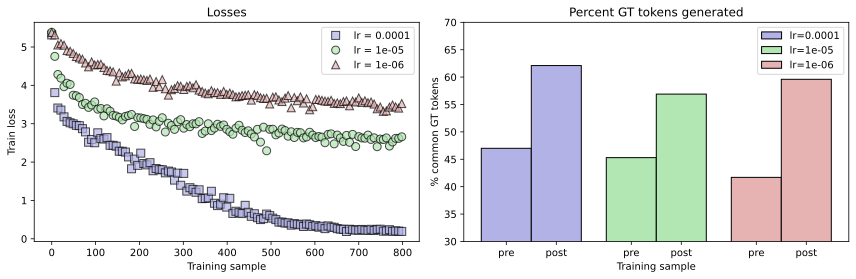

In [ ]:
_, axs = plt.subplots(1,2,figsize=(12,4))

colors = [[.7,.7,.9],[.7,.9,.7],[.9,.7,.7]]
shapes = 'so^'
edges_c = ['r','g','b']

# plot losses
for i in range(3):

  # plot the losses
  axs[0].plot(range(0,training_samples,7), losses[i][::7],f'k{shapes[i]}',markerfacecolor=colors[i],
              alpha=.7,markersize=8, label=f'lr = {learning_rates[i]}',color = 'k')

  # plot the percent of common GT tokens
  axs[1].bar([i-.2,i+.2], evals_pcts[i,:], width = .4, edgecolor = 'k',
             facecolor = colors[i], label=f'lr={learning_rates[i]}')

axs[0].set(xlabel='Training sample', ylabel = 'Train loss', title = 'Losses')
axs[0].legend()

axs[1].set(xlabel='Training sample', xticks=[-.2,.2,.8,1.2,1.8,2.2],
          xticklabels=['pre','post','pre','post','pre','post'],
          title='Percent GT tokens generated', ylabel='% common GT tokens', ylim=[30,70])
axs[1].legend()

plt.tight_layout()
plt.show()

* Smaller learning rates are generally preferred during fine-tuning
* There is a trade-off between preserving the base model and tweaking it towards the custom text. That balance depends on the application
* Quantitative metrics are important and useful, but obscure a lot. Qualitative assessments are crucial